# Libraries

In [1]:
from Lib.MultiLayerNet import *

CUDA not available, running on CPU


# Tunning Parameters

In [2]:
steps=5000
lr=1e-3
layers = [1,30,30,30,30,1]
# To generate new data:
min=-1
max=1
total_points=500
#Nu: Number of training points (2 as we onlt have 2 boundaries), # Nf: Number of collocation points (Evaluate PDE)
Nu=2
Nf=250

# Problem Setup

**Laplace Operator($\Delta$)**

$$\Delta u=u_{xx}+u_{yy} = \frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2}$$

**Harmonic Functions**

$$\Delta u =0$$

They are smooth

You need boundary conditions: you need the rate or the value.

You have to solve all points at the same time.

**Poisson equation**

$$\Delta u =f(x)$$

Example: Candle in a room

### Problem

$$-\Delta u=\pi^2sin(\pi x)$$

### Boundary Conditions:

$$u(-1)=0, u(1) =0$$

### Exact solution:

$$u(x)=sin(\pi x)$$

### PDE:
$$-\Delta u=\pi^2sin(\pi x)$$
$$u_{xx}=-\pi^2sin(\pi x)$$
$$\frac{\partial^2u}{\partial x^2}=-\pi^2sin(\pi x)$$

So the residual will be:

$$0=\frac{\partial^2u}{\partial x^2}+\pi^2sin(\pi x)$$

Note: Remeber that our neural network $NN(x)\approx u(x)$ so:

$$\frac{\partial^2NN}{\partial x^2}\approx\frac{\partial^2u}{\partial x^2}$$

$$f=\frac{\partial^2NN}{\partial x^2}+\pi^2sin(\pi x)\rightarrow 0$$


**Initial Conditions (Dirichlet BC)**
$$u(-1)=0$$

$$u(1)=0$$

Set a function to describe our boundary conditions:

$$f_{BC}(x)=1-|x|$$

Note: $f_{BC}$ is not the answer to our PDE, but it helps us describe the boundary condition (Generate data).

## Functions

In [3]:
def f_BC(x):
  return 1-torch.abs(x)
def f_real(x):
  return torch.sin(np.pi*x)
def PDE(x):
  return -1*(np.pi**2)*torch.sin(np.pi*x)


In [4]:
def mygrad(y, x):
    dydx = grad(y, x, torch.ones(x.size()[0], 1, device=dev),
                create_graph=True, retain_graph=True)[0]
    return dydx

### Neural Network

# Generate data

In [5]:
# get the analytical solution over the full domain
x = torch.linspace(min,max,total_points).view(-1,1) #prepare to NN
y = f_real(x)
print(x.shape, y.shape)


torch.Size([500, 1]) torch.Size([500, 1])


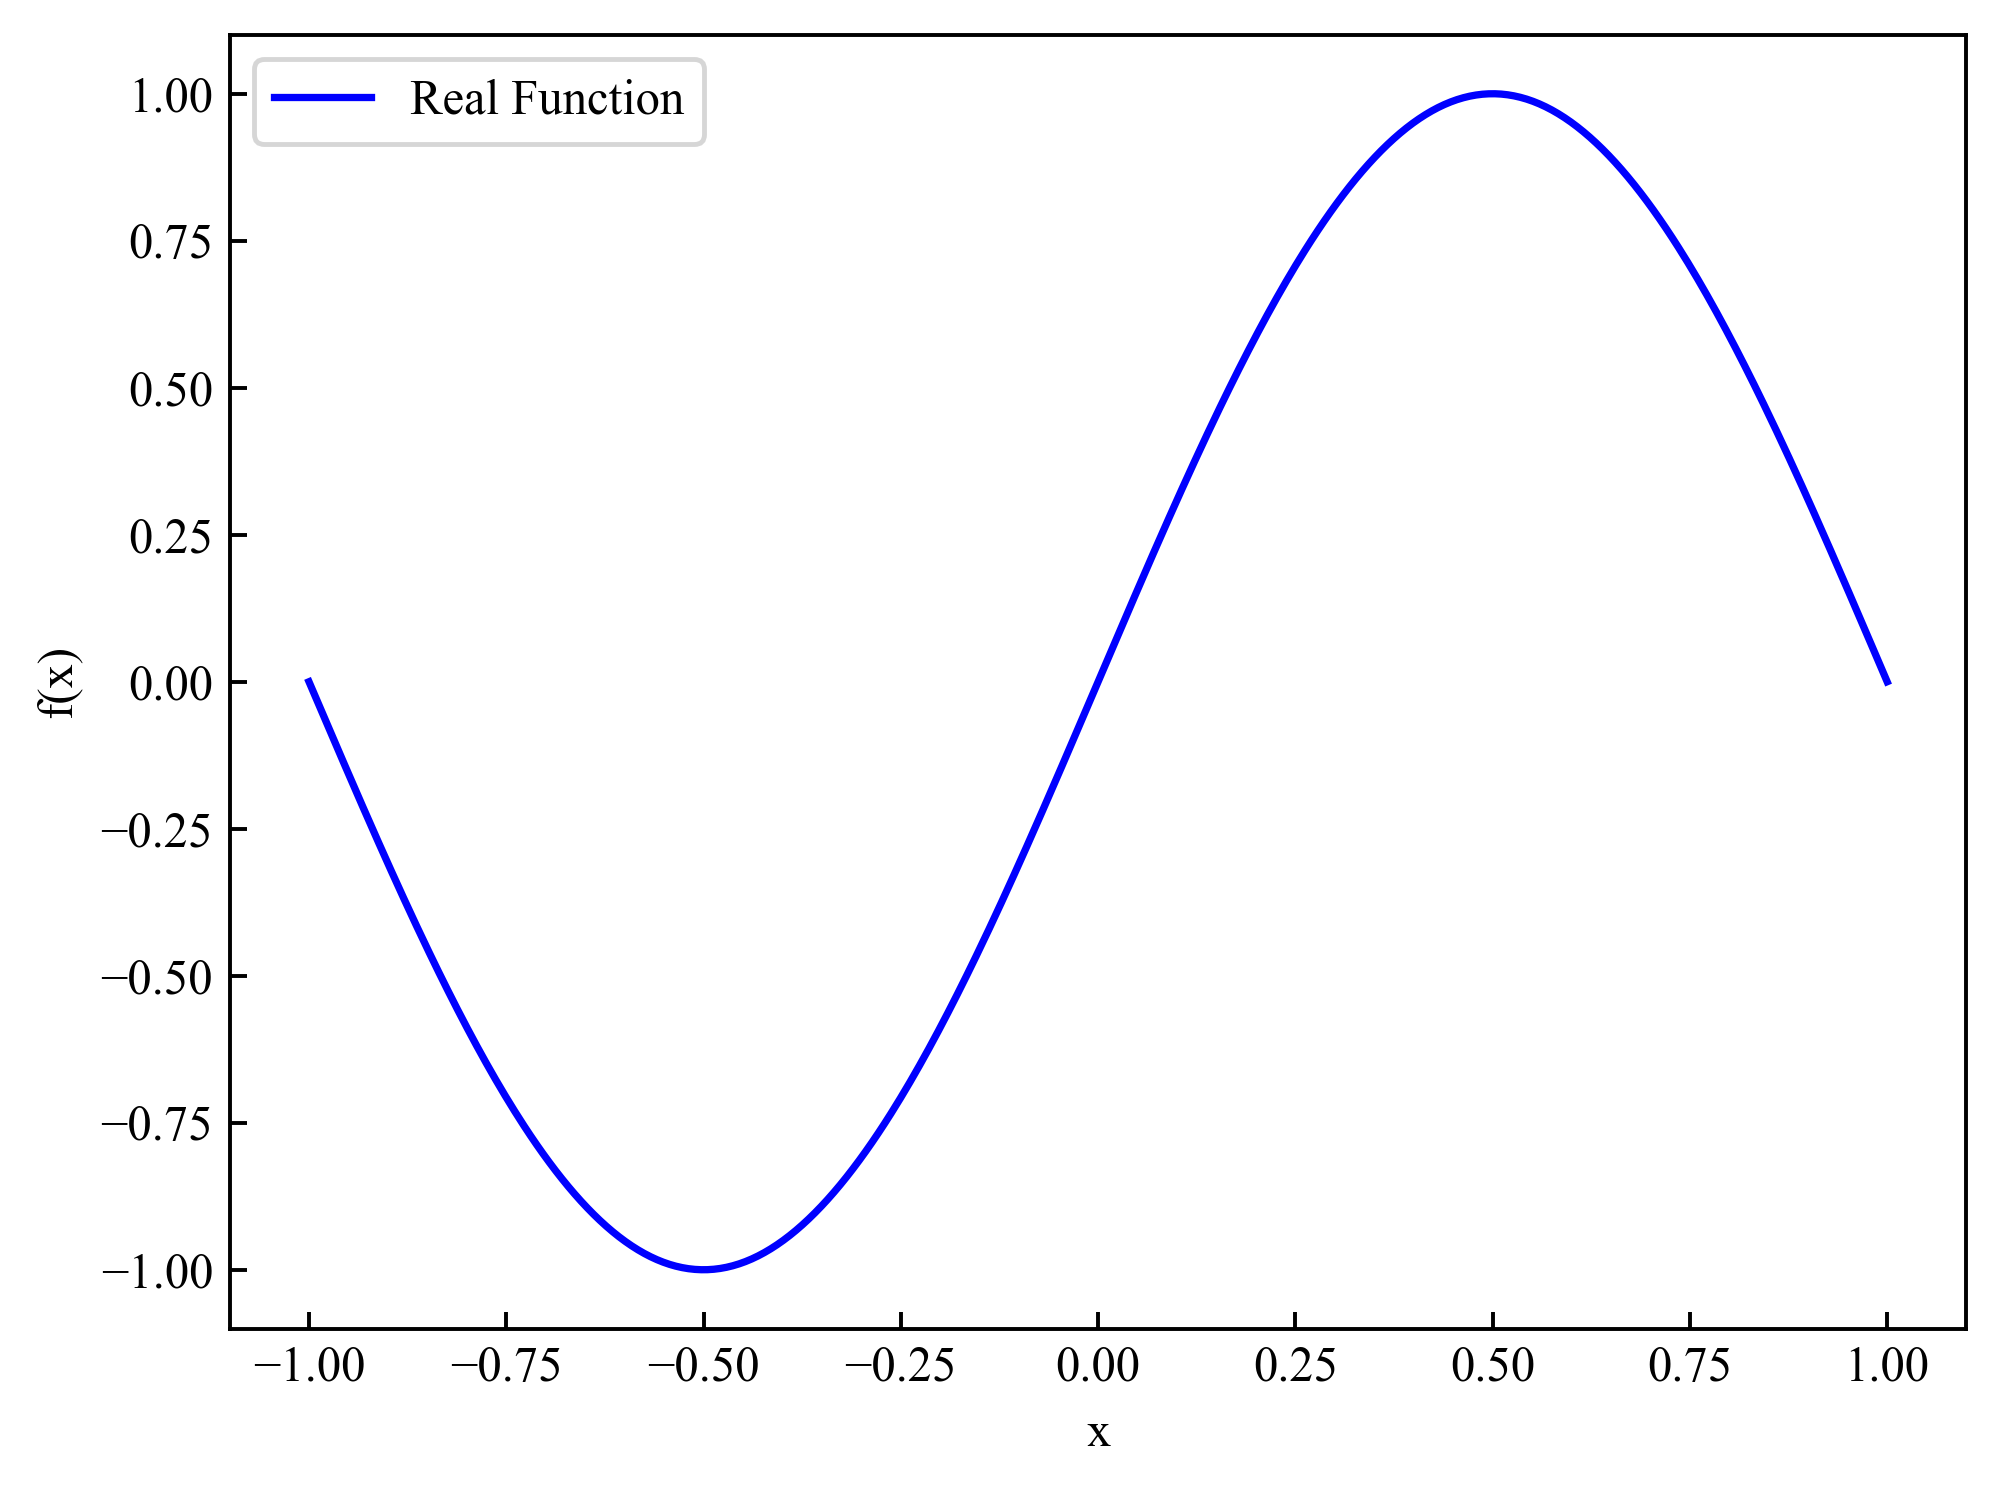

In [6]:
fig, ax1 = plt.subplots()
ax1.plot(x.detach().numpy(),y.detach().numpy(),color='blue',label='Real Function')
#ax1.plot(x_train.detach().numpy(),yh.detach().numpy(),color='red',label='Pred_Train')
ax1.set_xlabel('x',color='black')
ax1.set_ylabel('f(x)',color='black')
ax1.tick_params(axis='y', color='black')
ax1.legend(loc = 'upper left')

In [7]:
#def get_training_data(x):
#Nu: Number of training point, # Nf: Number of colloction points
# Set Boundary conditions x=min & x= max
BC_1=x[0,:]
BC_2=x[-1,:]
# Total Tpaining points BC1+BC2
x_BC=torch.vstack([BC_1,BC_2])
#Select Nf points
# Latin Hypercube sampling for collocation points 
x_PDE = BC_1 + (BC_2-BC_1)*lhs(1,Nf)
x_PDE = torch.vstack((x_PDE,x_BC)) 

/var/folders/mg/bm863m192j5fg04x2gsgcj940000gn/T/ipykernel_28045/3408708616.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x_PDE = BC_1 + (BC_2-BC_1)*lhs(1,Nf)


In [8]:
y_BC=f_BC(x_BC).to(dev)

# Train Neural Network

In [9]:
#Store tensors to GPU
x_PDE=x_PDE.float().to(dev)
x_BC=x_BC.to(dev)
x_PDE.requires_grad_(True)
x_BC.requires_grad_(True)

#Create Model
model = MultiLayerNet(layers, init=True)
model.to(dev)
optimizer = torch.optim.Adam(model.parameters(),lr=lr,amsgrad=False)
start_time = time.time()

Constructor: Init Network!


In [10]:
start_time = time.time()
it_time = time.time()
for i in range(steps):
    u = model(x_PDE)
    BCu = model(x_BC)
    dudx = mygrad(u, x_PDE)
    dudx2 = mygrad(dudx, x_PDE)
    loss_PDE = torch.mean(torch.square(dudx2 + torch.pi ** 2 * torch.sin(torch.pi * x_PDE)))
    loss_BC = torch.mean(torch.square(BCu))
    loss = loss_PDE+loss_BC
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if i%(steps/10)==0:
      print('Iter: %d  Loss: %.5e  Loss_PDE: %.5e  Loss_BC: %.5e  Time: %.3e'
                    % (i, loss.item(), loss_PDE.item(), loss_BC.item(), time.time() - it_time))
      torch.save(model.state_dict(), './output/Case3/model.pt')
      it_time = time.time()

Iter: 0  Loss: 4.61723e+01  Loss_PDE: 4.60350e+01  Loss_BC: 1.37358e-01  Time: 1.624e-02
Iter: 500  Loss: 3.18642e-03  Loss_PDE: 3.17906e-03  Loss_BC: 7.36158e-06  Time: 7.023e-01
Iter: 1000  Loss: 1.56688e-03  Loss_PDE: 1.56349e-03  Loss_BC: 3.38341e-06  Time: 6.985e-01
Iter: 1500  Loss: 7.08212e-04  Loss_PDE: 7.06894e-04  Loss_BC: 1.31795e-06  Time: 7.566e-01
Iter: 2000  Loss: 3.66056e-04  Loss_PDE: 3.65625e-04  Loss_BC: 4.31748e-07  Time: 6.999e-01
Iter: 2500  Loss: 2.32487e-04  Loss_PDE: 2.32311e-04  Loss_BC: 1.75682e-07  Time: 6.991e-01
Iter: 3000  Loss: 1.50434e-04  Loss_PDE: 1.50231e-04  Loss_BC: 2.02738e-07  Time: 8.388e-01
Iter: 3500  Loss: 7.90177e-05  Loss_PDE: 7.88782e-05  Loss_BC: 1.39528e-07  Time: 8.046e-01
Iter: 4000  Loss: 2.63386e-04  Loss_PDE: 2.52327e-04  Loss_BC: 1.10587e-05  Time: 7.651e-01
Iter: 4500  Loss: 2.17614e-05  Loss_PDE: 2.17557e-05  Loss_BC: 5.63694e-09  Time: 7.743e-01


### Plots

In [11]:
# Function
yh=model(x.to(dev))
y=f_real(x)
#Error
# print(model.lossBC(x.to(dev),f_real(x).to(dev)))

In [12]:
# Derivative
g=x.to(dev)
g=g.clone()
g.requires_grad=True #Enable differentiation
f=model(g)
f_x=mygrad(f,g)
# f_x=autograd.grad(f,g,torch.ones([g.shape[0],1]).to(dev),retain_graph=True, create_graph=True)[0]

In [13]:
# Detach from GPU
y_plot=y.detach().numpy()
yh_plot=yh.detach().cpu().numpy()
f_x_plot=f_x.detach().cpu().numpy()

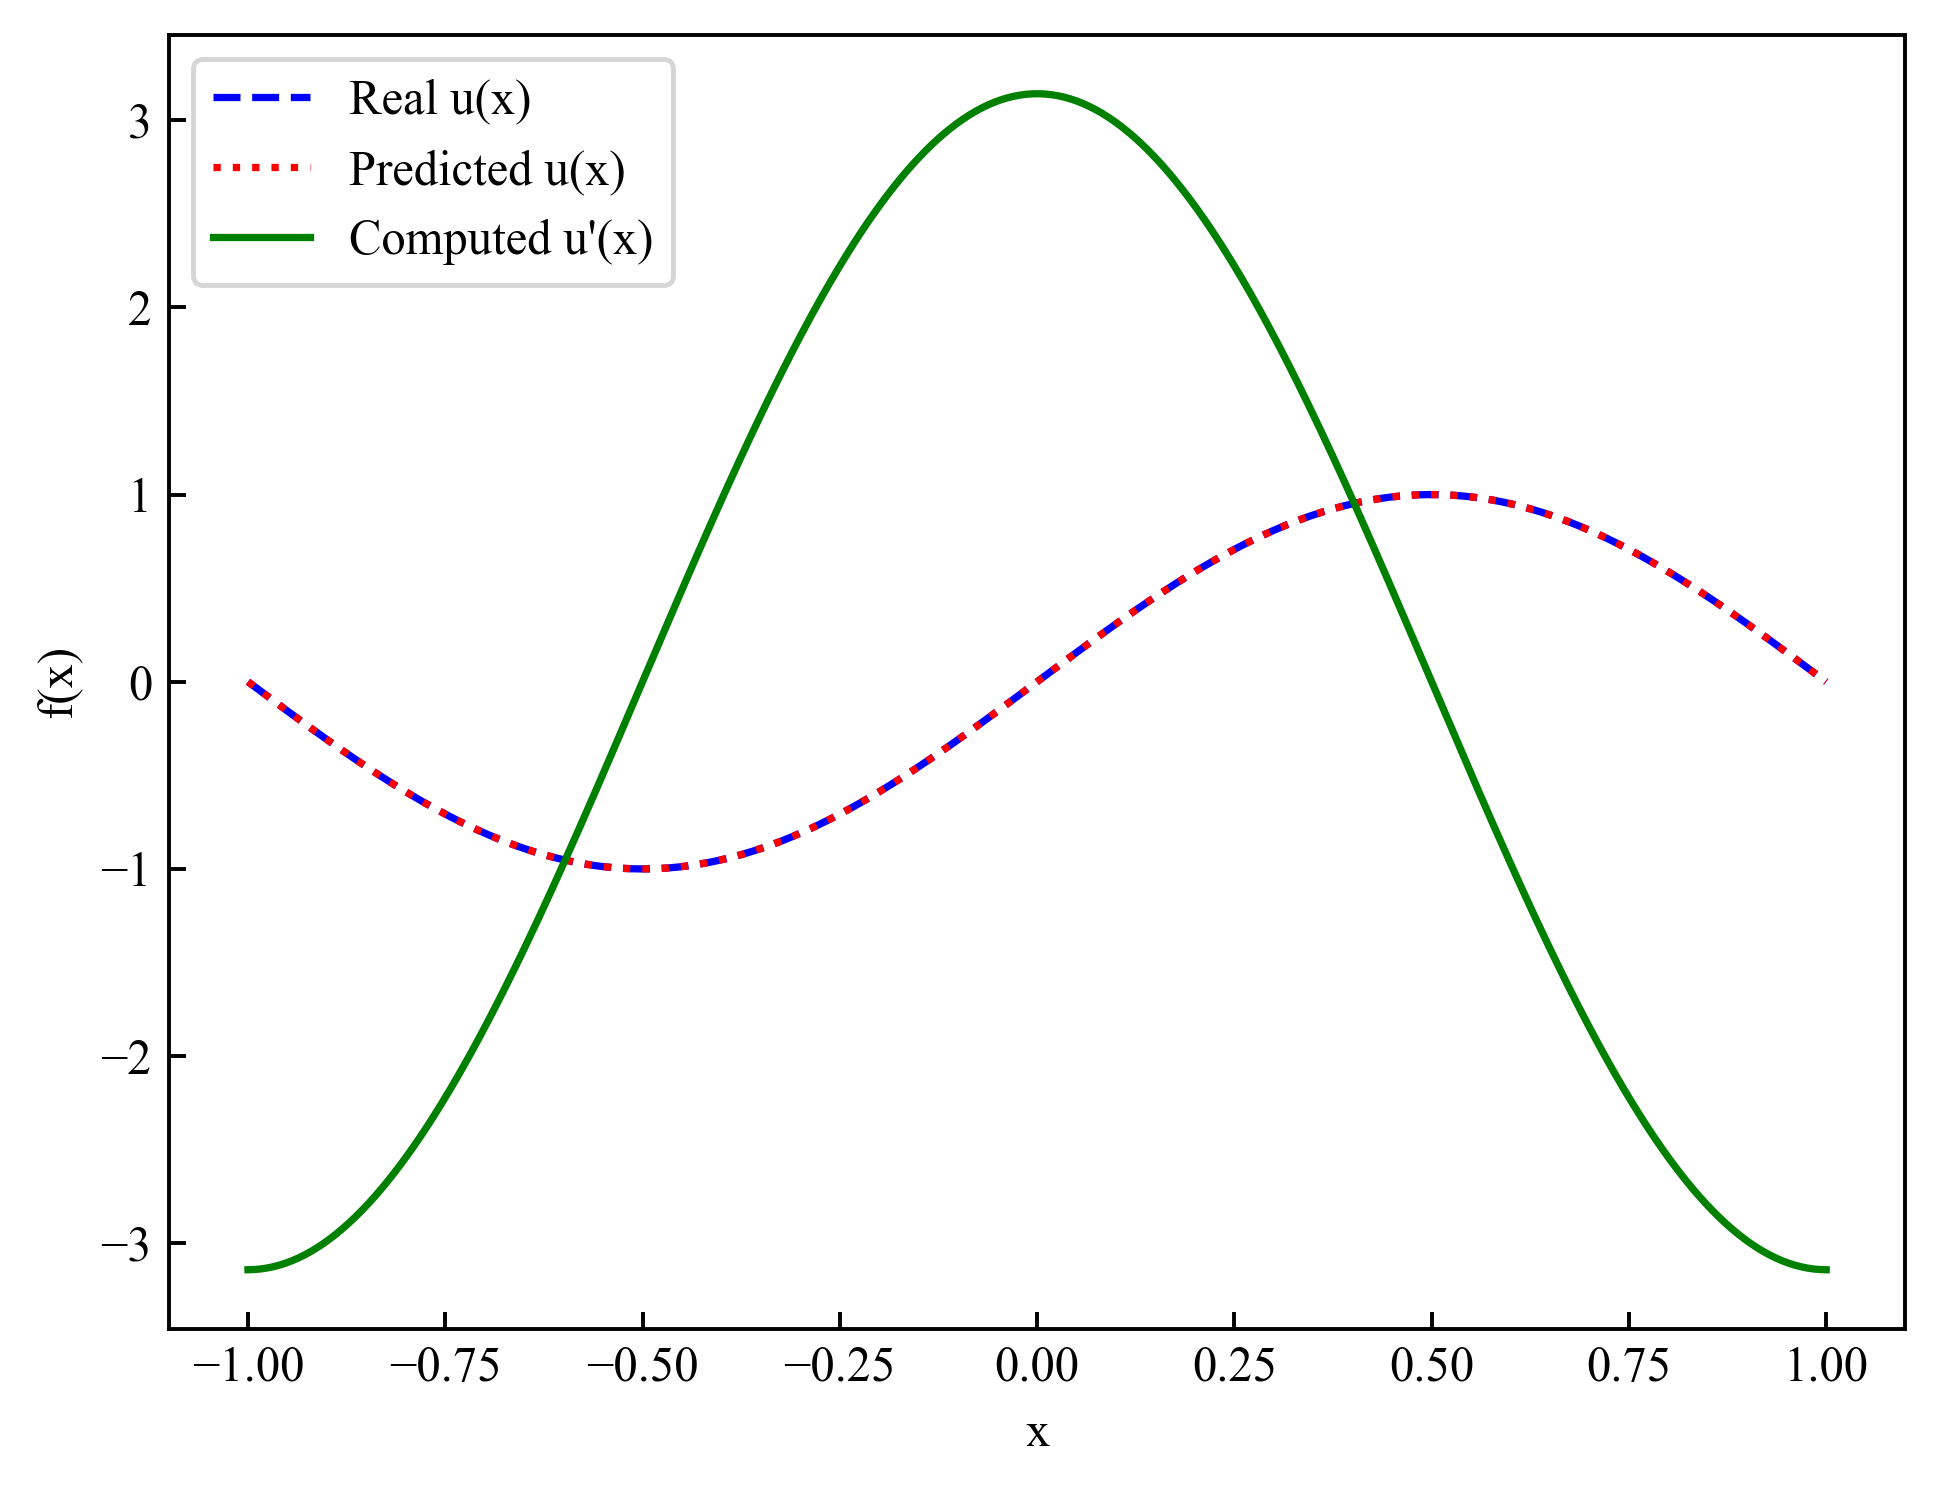

In [14]:
# Plot
fig, ax1 = plt.subplots()
ax1.plot(x,y_plot,'--',color='blue',label='Real u(x)')
ax1.plot(x,yh_plot,':',color='red',label='Predicted u(x)')
ax1.plot(x,f_x_plot,color='green',label='Computed u\'(x)')
ax1.set_xlabel('x',color='black')
ax1.set_ylabel('f(x)',color='black')
ax1.tick_params(axis='y', color='black')
ax1.legend(loc = 'upper left')